# Baseline Model (Ridge Regression)
This notebook trains a baseline regression model using the features extracted in `src/features.py`. We use GroupKFold cross-validation to prevent data leakage across wells.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.append(os.path.abspath('../src'))
from data_loader import get_all_well_ids, load_well_data
from features import extract_features_for_well

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [2]:
DATA_DIR = '../data'
well_ids = get_all_well_ids(DATA_DIR, split='train')

# For demonstration and speed, let's use the first 50 wells.
# To train on the full dataset, remove the slicing.
num_wells_to_use = 50
selected_wells = well_ids[:num_wells_to_use]
print(f"Processing {len(selected_wells)} wells...")

all_features = []
for wid in selected_wells:
    horz_df, type_df = load_well_data(wid, DATA_DIR, split='train')
    # Extract features
    df_feats = extract_features_for_well(wid, horz_df, type_df, is_train=True)
    if len(df_feats) > 0:
        all_features.append(df_feats)

dataset = pd.concat(all_features, ignore_index=True)
print(f"Dataset Shape: {dataset.shape}")
dataset.head()

Processing 50 wells...
Dataset Shape: (238595, 15)


,well_id,MD,X,Y,Z,GR,ps_TVT,ps_Z,ps_MD,ps_GR,delta_Z,delta_MD,dist_XY,inclination_proxy,TVT
0,000d7d20,12909.0,2983537.06,1070212.72,-9735.07,97.912430,11747.37,-9735.08,12908.0,NaN,0.01,1.0,1.000450,0.01,11747.38
1,000d7d20,12910.0,2983537.03,1070213.72,-9735.06,97.912430,11747.37,-9735.08,12908.0,NaN,0.02,2.0,2.000900,0.01,11747.39
2,000d7d20,12911.0,2983537.00,1070214.72,-9735.05,97.912430,11747.37,-9735.08,12908.0,NaN,0.03,3.0,3.001350,0.01,11747.40
3,000d7d20,12912.0,2983536.97,1070215.71,-9735.04,104.818205,11747.37,-9735.08,12908.0,NaN,0.04,4.0,3.991804,0.01,11747.40
4,000d7d20,12913.0,2983536.94,1070216.71,-9735.03,103.960888,11747.37,-9735.08,12908.0,NaN,0.05,5.0,4.992254,0.01,11747.41


In [3]:
# Prepare features and target
# We predict dTVT = TVT - ps_TVT instead of raw TVT. It's often easier for linear models to predict the delta.
dataset['target_dTVT'] = dataset['TVT'] - dataset['ps_TVT']

features = ['delta_Z', 'delta_MD', 'dist_XY', 'GR', 'inclination_proxy']

# Handle any remaining NaNs in features by filling with 0 or mean
X = dataset[features].fillna(0)
y = dataset['target_dTVT']
groups = dataset['well_id']

print(f"Features used: {features}")

Features used: ['delta_Z', 'delta_MD', 'dist_XY', 'GR', 'inclination_proxy']


In [4]:
# GroupKFold Cross-Validation
gkf = GroupKFold(n_splits=5)
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    # Train Ridge Regression
    model = Ridge(alpha=1.0)
    model.fit(X_train, y_train)
    
    # Predict (Delta TVT)
    preds_val = model.predict(X_val)
    
    # Calculate absolute TVT prediction to get actual RMSE in feet
    ps_TVT_val = dataset.iloc[val_idx]['ps_TVT'].values
    pred_abs_TVT = ps_TVT_val + preds_val
    true_abs_TVT = dataset.iloc[val_idx]['TVT'].values
    
    score = root_mean_squared_error(true_abs_TVT, pred_abs_TVT)
    rmse_scores.append(score)
    print(f"Fold {fold+1} RMSE: {score:.2f} feet")

print(f"\nAverage CV RMSE: {np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f} feet")

Fold 1 RMSE: 10.68 feet
Fold 2 RMSE: 13.28 feet
Fold 3 RMSE: 9.09 feet
Fold 4 RMSE: 14.26 feet
Fold 5 RMSE: 13.63 feet

Average CV RMSE: 12.19 ± 1.97 feet


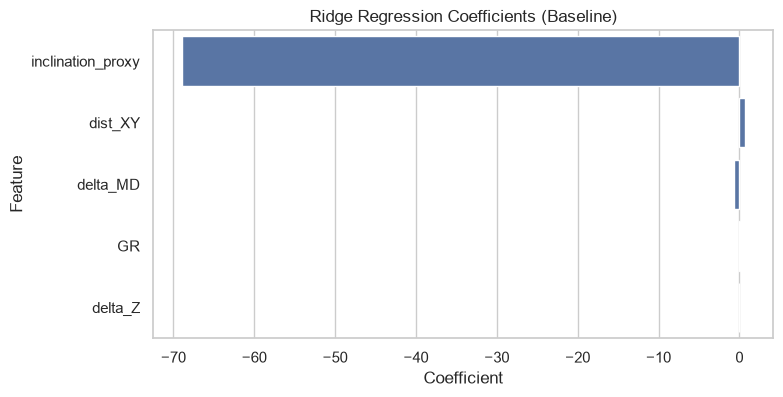

In [5]:
# Feature Importance (Coefficients)
model = Ridge(alpha=1.0)
model.fit(X, y)

coef_df = pd.DataFrame({'Feature': features, 'Coefficient': model.coef_})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Abs_Coef', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x='Coefficient', y='Feature', data=coef_df)
plt.title('Ridge Regression Coefficients (Baseline)')
plt.show()